<a href="https://colab.research.google.com/github/amrithavi/GENE-PAPER/blob/main/DNALSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install -q tensorflow pandas scikit-learn

In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, accuracy_score

In [3]:
from google.colab import files
files.upload()

KeyboardInterrupt: 

In [ ]:
import zipfile, os

zip_path = "/content/archive (3) (1).zip"   # <-- IMPORTANT

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/data")

print(os.listdir("/content/data"))

['train.csv', 'validation.csv', 'test.csv']


In [ ]:
train_df = pd.read_csv("/content/data/train.csv")
val_df   = pd.read_csv("/content/data/validation.csv")
test_df  = pd.read_csv("/content/data/test.csv")

train_df.head()

,Unnamed: 0,NCBIGeneID,Symbol,Description,GeneType,GeneGroupMethod,NucleotideSequence
0,0,106481178,RNU4-21P,"RNA, U4 small nuclear 21, pseudogene",PSEUDO,NCBI Ortholog,<AGCTTAGCACAGTGGCAGTATCATAGGCAGTGAGGTTTATCCGAG...
1,1,123477792,LOC123477792,Sharpr-MPRA regulatory region 12926,BIOLOGICAL_REGION,NCBI Ortholog,<CTGGAGCGGCCACGATGTGAACTGTCACCGGCCACTGCTGCTCCG...
2,2,113174975,LOC113174975,Sharpr-MPRA regulatory region 7591,BIOLOGICAL_REGION,NCBI Ortholog,<TTCCCAATTTTTCCTCTGCTTTTTAATTTTCTAGTTTCCTTTTTC...
3,3,116216107,LOC116216107,CRISPRi-validated cis-regulatory element chr10...,BIOLOGICAL_REGION,NCBI Ortholog,<CGCCCAGGCTGGAGTGCAGTGGCGCCATCTCGGCTCACTGCAGGC...
4,4,28502,IGHD2-21,immunoglobulin heavy diversity 2-21,OTHER,NCBI Ortholog,<AGCATATTGTGGTGGTGACTGCTATTCC>


In [ ]:
def clean_df(df):
    if "Unnamed: 0" in df.columns:
        df = df.drop(columns=["Unnamed: 0"])
    df = df.dropna()
    return df

train_df = clean_df(train_df)
val_df   = clean_df(val_df)
test_df  = clean_df(test_df)

In [ ]:
# Drop classes with too few examples to be learnable
train_df = train_df[train_df["GeneType"] != "scRNA"]
val_df   = val_df[val_df["GeneType"] != "scRNA"]
test_df  = test_df[test_df["GeneType"] != "scRNA"]

print(train_df["GeneType"].value_counts())

GeneType
PSEUDO               10220
BIOLOGICAL_REGION     6925
ncRNA                 2497
snoRNA                1148
PROTEIN_CODING         524
tRNA                   488
OTHER                  366
rRNA                   277
snRNA                  145
Name: count, dtype: int64


In [ ]:
print(train_df["GeneType"].value_counts())

GeneType
PSEUDO               10220
BIOLOGICAL_REGION     6925
ncRNA                 2497
snoRNA                1148
PROTEIN_CODING         524
tRNA                   488
OTHER                  366
rRNA                   277
snRNA                  145
Name: count, dtype: int64


In [ ]:
dna_tokenizer = Tokenizer(char_level=True)
dna_tokenizer.fit_on_texts(train_df["NucleotideSequence"])

X_train_seq = dna_tokenizer.texts_to_sequences(train_df["NucleotideSequence"])
X_val_seq   = dna_tokenizer.texts_to_sequences(val_df["NucleotideSequence"])
X_test_seq  = dna_tokenizer.texts_to_sequences(test_df["NucleotideSequence"])

MAX_LEN = 500

X_train_seq = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_val_seq   = pad_sequences(X_val_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_seq  = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post")

In [ ]:
tfidf = TfidfVectorizer(max_features=3000)

X_train_text = tfidf.fit_transform(train_df["Description"]).toarray()
X_val_text   = tfidf.transform(val_df["Description"]).toarray()
X_test_text  = tfidf.transform(test_df["Description"]).toarray()

In [ ]:
le = LabelEncoder()

y_train = le.fit_transform(train_df["GeneType"])
y_val   = le.transform(val_df["GeneType"])
y_test  = le.transform(test_df["GeneType"])

num_classes = len(le.classes_)

In [ ]:
# --- DNA Branch ---
seq_input = Input(shape=(MAX_LEN,))
x = Embedding(input_dim=len(dna_tokenizer.word_index)+1, output_dim=8)(seq_input)
x = LSTM(64)(x)
x = Dropout(0.3)(x)

# --- Text Branch ---
text_input = Input(shape=(X_train_text.shape[1],))
y = Dense(256, activation="relu")(text_input)
y = Dropout(0.3)(y)

# --- Fusion ---
combined = Concatenate()([x, y])
z = Dense(128, activation="relu")(combined)
z = Dropout(0.3)(z)
output = Dense(num_classes, activation="softmax")(z)

model = Model(inputs=[seq_input, text_input], outputs=output)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 500)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 500, 8)    │         56 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 3000)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     18,688 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    768,256 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 320)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     41,088 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 9)         │      1,161 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 829,249 (3.16 MB)

 Trainable params: 829,249 (3.16 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))

history = model.fit(
    [X_train_seq, X_train_text],
    y_train,
    validation_data=([X_val_seq, X_val_text], y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weight_dict
)

Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 14s 25ms/step - accuracy: 0.8423 - loss: 0.5450 - val_accuracy: 0.9515 - val_loss: 0.1886
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.9606 - loss: 0.0789 - val_accuracy: 0.9703 - val_loss: 0.1165
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9680 - loss: 0.0618 - val_accuracy: 0.9709 - val_loss: 0.1110
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.9689 - loss: 0.0553 - val_accuracy: 0.9718 - val_loss: 0.1037
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.9703 - loss: 0.0497 - val_accuracy: 0.9723 - val_loss: 0.1018
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9698 - loss: 0.0504 - val_accuracy: 0.9736 - val_loss: 0.1067
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.9709 - loss: 0.0461 - val_accuracy: 0.9716 - val_loss: 0.0983
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.9714 - loss: 0.0454 - val_ac

In [ ]:
pred = model.predict([X_test_seq, X_test_text])
pred_classes = np.argmax(pred, axis=1)

print("Accuracy:", accuracy_score(y_test, pred_classes))
print(classification_report(y_test, pred_classes, target_names=le.classes_))

261/261 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Accuracy: 0.9762162162162162
                   precision    recall  f1-score   support

BIOLOGICAL_REGION       1.00      1.00      1.00      2651
            OTHER       0.98      1.00      0.99       133
   PROTEIN_CODING       0.90      0.95      0.92       184
           PSEUDO       1.00      0.95      0.97      3800
            ncRNA       0.98      1.00      0.99       894
             rRNA       1.00      1.00      1.00        72
            snRNA       0.38      1.00      0.55        38
           snoRNA       0.84      1.00      0.91       405
             tRNA       0.92      1.00      0.96       148

         accuracy                           0.98      8325
        macro avg       0.89      0.99      0.92      8325
     weighted avg       0.98      0.98      0.98      8325



In [ ]:
def predict_gene(sequence, description):
    seq = dna_tokenizer.texts_to_sequences([sequence])
    seq = pad_sequences(seq, maxlen=MAX_LEN, padding="post", truncating="post")

    text = tfidf.transform([description]).toarray()

    pred = model.predict([seq, text])
    return le.inverse_transform([np.argmax(pred)])

predict_gene("ATCGGCTAGCTAGCTA", "regulatory region involved in transcription")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


array(['BIOLOGICAL_REGION'], dtype=object)

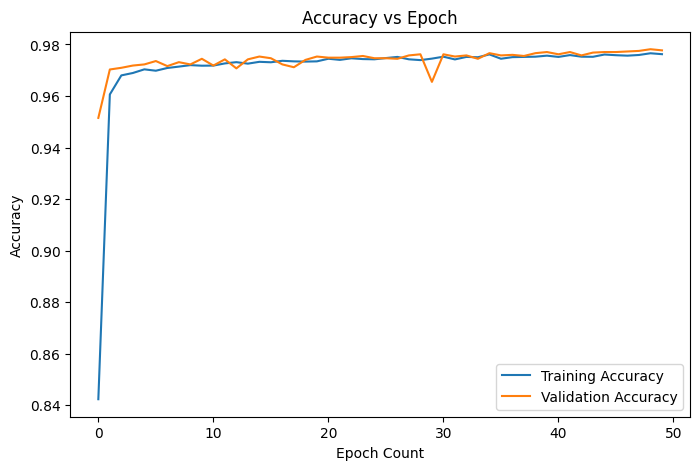

In [ ]:
import matplotlib.pyplot as plt

# Plot Accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.xlabel("Epoch Count")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend(["Training Accuracy", "Validation Accuracy"])

plt.show()

In [ ]:
import pickle

model.save("gene_model.h5")

with open("dna_tokenizer.pkl", "wb") as f:
    pickle.dump(dna_tokenizer, f)

with open("tfidf.pkl", "wb") as f:
    pickle.dump(tfidf, f)

with open("label_encoder.pkl", "wb") as f:
    pickle.dump(le, f)

from google.colab import files
files.download("gene_model.h5")
files.download("dna_tokenizer.pkl")
files.download("tfidf.pkl")
files.download("label_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

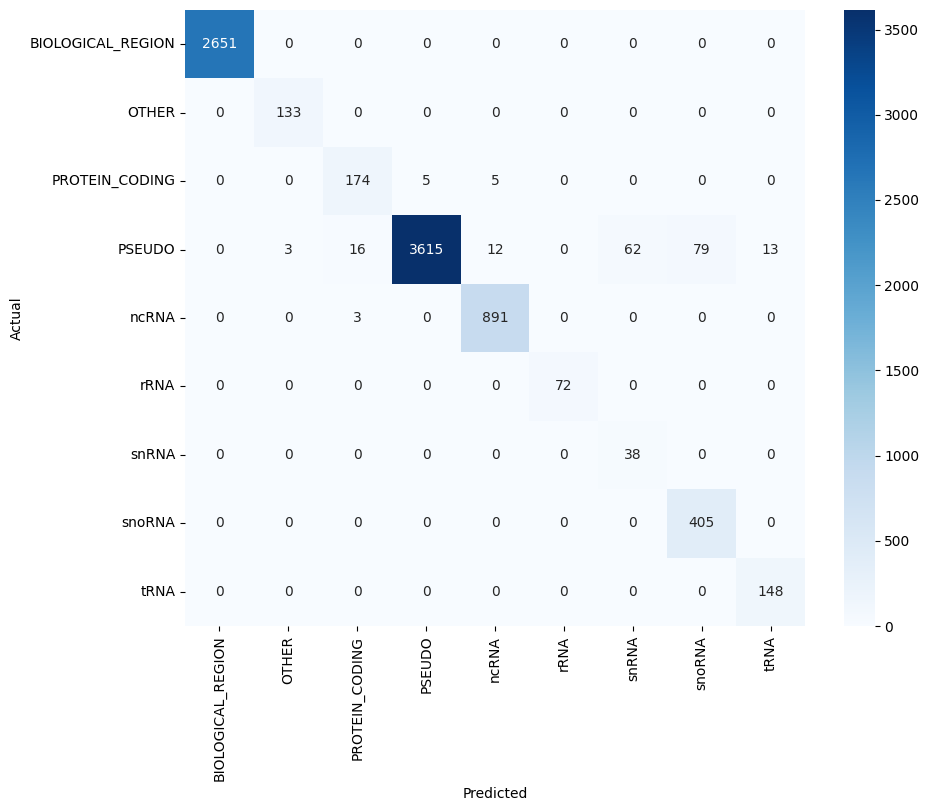

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred_classes)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
import random

results = []
for seed in [0, 1, 2, 3, 4]:
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    model = Model(inputs=[seq_input, text_input], outputs=output)  # rebuild fresh
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    model.fit([X_train_seq, X_train_text], y_train,
              validation_data=([X_val_seq, X_val_text], y_val),
              epochs=50, batch_size=64, class_weight=class_weight_dict, verbose=0)

    pred = model.predict([X_test_seq, X_test_text])
    pred_classes = np.argmax(pred, axis=1)
    acc = accuracy_score(y_test, pred_classes)
    results.append(acc)
    print(f"Seed {seed}: {acc:.4f}")

print(f"Mean: {np.mean(results):.4f}, Std: {np.std(results):.4f}")

261/261 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Seed 0: 0.9773
261/261 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Seed 1: 0.9778
261/261 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Seed 2: 0.9780
261/261 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Seed 3: 0.9775
261/261 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Seed 4: 0.9785
Mean: 0.9778, Std: 0.0004


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

In [ ]:
# --- Ablation 1: LSTM-only with class weights ---

seq_input = Input(
    shape=(MAX_LEN,)
)

x = Embedding(
    input_dim=len(dna_tokenizer.word_index) + 1,
    output_dim=8
)(seq_input)

x = LSTM(64)(x)
x = Dropout(0.3)(x)

x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

output_lstm = Dense(
    num_classes,
    activation="softmax"
)(x)

model_lstm = Model(
    inputs=seq_input,
    outputs=output_lstm
)

model_lstm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# --- Train with class weights ---
history_lstm = model_lstm.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weight_dict,
    verbose=1
)

# --- Evaluate ---
pred_lstm = np.argmax(
    model_lstm.predict(X_test_seq, verbose=0),
    axis=1
)

accuracy_lstm = accuracy_score(
    y_test,
    pred_lstm
)

weighted_f1_lstm = f1_score(
    y_test,
    pred_lstm,
    average="weighted"
)

macro_f1_lstm = f1_score(
    y_test,
    pred_lstm,
    average="macro"
)

print("LSTM-only accuracy:", accuracy_lstm)
print("LSTM-only weighted F1:", weighted_f1_lstm)
print("LSTM-only macro F1:", macro_f1_lstm)

print(
    classification_report(
        y_test,
        pred_lstm,
        target_names=le.classes_
    )
)

Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.0832 - loss: 2.0258 - val_accuracy: 0.0260 - val_loss: 2.0633
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.0648 - loss: 1.9958 - val_accuracy: 0.0367 - val_loss: 2.0858
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.0696 - loss: 1.9696 - val_accuracy: 0.0367 - val_loss: 2.0630
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.0668 - loss: 1.9059 - val_accuracy: 0.2731 - val_loss: 1.9819
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.2879 - loss: 1.7073 - val_accuracy: 0.2941 - val_loss: 1.6102
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.0785 - loss: 1.9138 - val_accuracy: 0.0302 - val_loss: 2.0558
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.2663 - loss: 1.6831 - val_accuracy: 0.2851 - val_loss: 1.6021
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.2982 - loss: 1.6333 - val_ac

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout

from sklearn.metrics import accuracy_score, classification_report


In [ ]:
######

In [ ]:
# --- Create TF-IDF features ---

from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
print(type(X_train_text))
print(X_train_text.shape)
print(X_train_text[:2])

<class 'numpy.ndarray'>
(22590, 3000)
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [ ]:
[name for name in globals() if "tfidf" in name.lower()]

['TfidfVectorizer', 'tfidf', 'tfidf_vectorizer']

In [ ]:
# Your existing variables are already TF-IDF matrices
X_train_tfidf = X_train_text
X_val_tfidf = X_val_text
X_test_tfidf = X_test_text

print("Train TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Train TF-IDF shape: (22590, 3000)
Validation TF-IDF shape: (4577, 3000)
Test TF-IDF shape: (8325, 3000)


In [ ]:
text_input = Input(
    shape=(X_train_tfidf.shape[1],)
)

y_ = Dense(
    256,
    activation="relu"
)(text_input)

y_ = Dropout(0.3)(y_)

y_ = Dense(
    128,
    activation="relu"
)(y_)

y_ = Dropout(0.3)(y_)

output_tfidf = Dense(
    num_classes,
    activation="softmax"
)(y_)

model_tfidf = Model(
    inputs=text_input,
    outputs=output_tfidf
)

model_tfidf.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_tfidf.fit(
    X_train_tfidf,
    y_train,
    validation_data=(X_val_tfidf, y_val),
    epochs=50,
    batch_size=64,
    verbose=1
)

pred_tfidf = np.argmax(
    model_tfidf.predict(X_test_tfidf),
    axis=1
)

print(
    "TF-IDF-only accuracy:",
    accuracy_score(y_test, pred_tfidf)
)

print(
    classification_report(
        y_test,
        pred_tfidf,
        target_names=le.classes_
    )
)

Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.9006 - loss: 0.3916 - val_accuracy: 0.9738 - val_loss: 0.0758
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9715 - loss: 0.0813 - val_accuracy: 0.9784 - val_loss: 0.0567
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9757 - loss: 0.0659 - val_accuracy: 0.9795 - val_loss: 0.0508
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9763 - loss: 0.0603 - val_accuracy: 0.9797 - val_loss: 0.0496
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9779 - loss: 0.0569 - val_accuracy: 0.9812 - val_loss: 0.0474
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9784 - loss: 0.0556 - val_accuracy: 0.9812 - val_loss: 0.0465
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9788 - loss: 0.0536 - val_accuracy: 0.9810 - val_loss: 0.0453
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9790 - loss: 0.0530 - val_accuracy: 0

In [ ]:
# --- Baseline: Logistic Regression on TF-IDF ---

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score

logreg = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)

logreg.fit(
    X_train_text,
    y_train
)

pred_lr = logreg.predict(
    X_test_text
)

accuracy_lr = accuracy_score(
    y_test,
    pred_lr
)

weighted_f1_lr = f1_score(
    y_test,
    pred_lr,
    average="weighted"
)

macro_f1_lr = f1_score(
    y_test,
    pred_lr,
    average="macro"
)

print("Logistic Regression accuracy:", accuracy_lr)
print("Logistic Regression weighted F1:", weighted_f1_lr)
print("Logistic Regression macro F1:", macro_f1_lr)

print(
    classification_report(
        y_test,
        pred_lr,
        target_names=le.classes_
    )
)

Logistic Regression accuracy: 0.9748948948948949
Logistic Regression weighted F1: 0.9745972542638557
Logistic Regression macro F1: 0.9133910857044059
                   precision    recall  f1-score   support

BIOLOGICAL_REGION       1.00      1.00      1.00      2651
            OTHER       0.94      0.99      0.97       133
   PROTEIN_CODING       0.94      0.71      0.81       184
           PSEUDO       0.98      0.97      0.97      3800
            ncRNA       0.98      0.99      0.98       894
             rRNA       1.00      1.00      1.00        72
            snRNA       0.69      0.63      0.66        38
           snoRNA       0.88      0.96      0.92       405
             tRNA       0.85      0.97      0.91       148

         accuracy                           0.97      8325
        macro avg       0.92      0.91      0.91      8325
     weighted avg       0.98      0.97      0.97      8325



In [ ]:
for cls in train_df["GeneType"].unique():
    print(f"\n=== {cls} ===")
    print(train_df[train_df["GeneType"] == cls]["Description"].head(5).tolist())


=== PSEUDO ===
['RNA, U4 small nuclear 21, pseudogene', 'U7 small nuclear RNA', 'RNA, 7SL, cytoplasmic 181, pseudogene', 'RNA, U6 small nuclear 1048, pseudogene', 'leucine rich repeat containing 37 member A13, pseudogene']

=== BIOLOGICAL_REGION ===
['Sharpr-MPRA regulatory region 12926', 'Sharpr-MPRA regulatory region 7591', 'CRISPRi-validated cis-regulatory element chr10.180', 'OCT4-NANOG-H3K27ac hESC enhancer GRCh37_chr12:79941058-79941786', 'Sharpr-MPRA regulatory region 6001']

=== OTHER ===
['immunoglobulin heavy diversity 2-21', 'T cell receptor alpha variable 17', 'immunoglobulin lambda variable 10-54', 'immunoglobulin heavy diversity 5-12', 'T cell receptor alpha joining 7']

=== snoRNA ===
['small nucleolar RNA SNORA27', 'small nucleolar RNA U13', 'small nucleolar RNA SNORA32', 'small nucleolar RNA, C/D box 45B', 'small nucleolar RNA, C/D box 73A']

=== PROTEIN_CODING ===
['H2A clustered histone 4', 'H2B clustered histone 8', 'ribonuclease A family member 8', 'family with se

In [ ]:
import re

leak_terms = [
    "pseudogene", "regulatory region", "cis-regulatory", "enhancer",
    "small nucleolar", "small nuclear", "spliceosomal", "ribosomal",
    "microrna", "uncharacterized", "trna", "immunoglobulin",
    "t cell receptor", "histone", "olfactory receptor", "mpra"
]

def strip_leakage(text):
    t = str(text).lower()
    for term in leak_terms:
        t = t.replace(term, "")
    return t

train_df["Description_clean"] = train_df["Description"].apply(strip_leakage)
val_df["Description_clean"]   = val_df["Description"].apply(strip_leakage)
test_df["Description_clean"]  = test_df["Description"].apply(strip_leakage)

tfidf_clean = TfidfVectorizer(max_features=3000)
X_train_text_clean = tfidf_clean.fit_transform(train_df["Description_clean"]).toarray()
X_val_text_clean   = tfidf_clean.transform(val_df["Description_clean"]).toarray()
X_test_text_clean  = tfidf_clean.transform(test_df["Description_clean"]).toarray()

logreg_clean = LogisticRegression(max_iter=1000)
logreg_clean.fit(X_train_text_clean, y_train)
pred_clean = logreg_clean.predict(X_test_text_clean)
print("LogReg (leakage-stripped):", accuracy_score(y_test, pred_clean))
print(classification_report(y_test, pred_clean, target_names=le.classes_))

LogReg (leakage-stripped): 0.9404204204204204
                   precision    recall  f1-score   support

BIOLOGICAL_REGION       1.00      1.00      1.00      2651
            OTHER       0.82      0.84      0.83       133
   PROTEIN_CODING       0.75      0.28      0.41       184
           PSEUDO       0.94      0.93      0.94      3800
            ncRNA       0.85      0.99      0.91       894
             rRNA       0.91      1.00      0.95        72
            snRNA       0.88      0.18      0.30        38
           snoRNA       0.88      0.92      0.90       405
             tRNA       0.85      0.94      0.89       148

         accuracy                           0.94      8325
        macro avg       0.88      0.79      0.79      8325
     weighted avg       0.94      0.94      0.94      8325

